# Constraint Satisfaction Problem : Graph coloring


## Create Data

We can create a planar graph with $n$ vertices by randomly placing $n$ points in 2-dimensional Euclidean space and then performing a [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation).

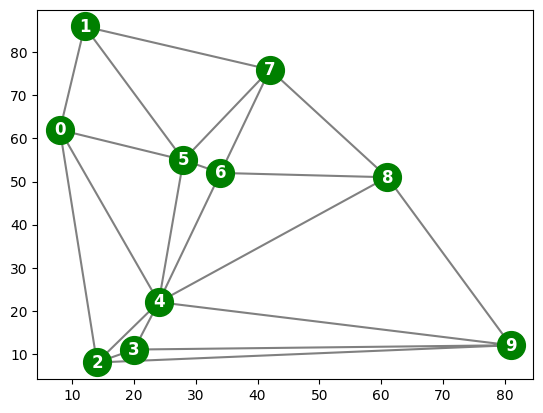

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay

np.random.seed(1111)

# create points and sort them by 
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:,0])
points = points[o,:]


# triangulate
tri = Delaunay(points)


# plot
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")
plt.plot(points[:,0], points[:,1], 'o', color = "green", markersize = 20)

for i in range(len(points)):
       plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

The triangulation can be converted into a list with an array of neighbor vertex indices for each point (see man page for [scipy.spatial.Delaunay](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)). 

In [2]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []

for k in range(len(indptr)-1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k+1]]))
    
neighbors

[array([1, 2, 4, 5], dtype=int32),
 array([0, 5, 7], dtype=int32),
 array([0, 3, 4, 9], dtype=int32),
 array([2, 4, 9], dtype=int32),
 array([0, 2, 3, 5, 6, 8, 9], dtype=int32),
 array([0, 1, 4, 6, 7], dtype=int32),
 array([4, 5, 7, 8], dtype=int32),
 array([1, 5, 6, 8], dtype=int32),
 array([4, 6, 7, 9], dtype=int32),
 array([2, 3, 4, 8], dtype=int32)]

The first row are the indices for the points neighboring point 0.

## Define CSP

The problem is defined as a dictionary with variable names, a dictionary with domain values for each variable and a set of binary  not-equal constraints (tuples of variables that are not allowed to have the same value).  

In [3]:
variables = [str(var) for var in range(n)]

domain = ['red', 'blue', 'green', 'orange']
#domain = ['red', 'blue', 'green']
domains = {}
for v in variables: 
    domains[v] = domain

# create binary constraints
constraints = {}
for i in range(len(neighbors)):
    for j in neighbors[i]:
        if(i<j): constraints[tuple([str(i), str(j)])] = True
constraints = constraints.keys()

csp = {'variables': variables, 'domains': domains, 'constraints': constraints, }
csp

{'variables': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'],
 'domains': {'0': ['red', 'blue', 'green', 'orange'],
  '1': ['red', 'blue', 'green', 'orange'],
  '2': ['red', 'blue', 'green', 'orange'],
  '3': ['red', 'blue', 'green', 'orange'],
  '4': ['red', 'blue', 'green', 'orange'],
  '5': ['red', 'blue', 'green', 'orange'],
  '6': ['red', 'blue', 'green', 'orange'],
  '7': ['red', 'blue', 'green', 'orange'],
  '8': ['red', 'blue', 'green', 'orange'],
  '9': ['red', 'blue', 'green', 'orange']},
 'constraints': dict_keys([('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')])}

## Check Completeness and Consistency

`assignment` is a dictionary. Assigned variables have an entry with the variable name as the key. `{}` is therefore the empty assignment.

In [4]:
def complete(assignment, csp):
    return(all([v in assignment.keys() for v in csp['variables']])) 

print("complete({}, csp) =", complete({}, csp))

print("complete({...complete list...}, csp) =", 
      complete({'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red', 
          '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}, csp))

complete({}, csp) = False
complete({...complete list...}, csp) = True


In [5]:
def consistent(assignment, csp):
    for constr in csp['constraints']:
        if(constr[0] in assignment.keys() and constr[1] in assignment.keys()):
            if assignment[constr[0]] == assignment[constr[1]]: return(False)
        
    return(True)
        
print("consistent({}, csp) =", consistent({}, csp))
print("consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) =", 
      consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp))

consistent({}, csp) = True
consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) = False


## Implement Simple Backtracking Search

In [6]:
# Các cờ bật/tắt chiến lược. Mặc định tắt hết = đúng phiên bản gốc của notebook
USE_MRV = False   # Bài 3: chọn biến theo Minimum Remaining Values
USE_LCV = False   # Bài 3: sắp xếp thứ tự giá trị theo Least Constraining Value
USE_FC = False    # Bài 4: Forward Checking
NEIGHBORS = {}    # đỉnh -> danh sách đỉnh kề (suy ra từ csp['constraints'], được gán trong backtrack_search)
FC_DOMAINS = {}   # miền còn hợp lệ của từng đỉnh khi dùng Forward Checking

# Variable ordering: phiên bản gốc chọn biến chưa gán đầu tiên; khi USE_MRV = True chọn biến có ít giá trị hợp lệ nhất
def select_unassigned_var(assignment, csp):
    if(complete(assignment, csp)): return(None)
    
    if not USE_MRV:
        return(csp['variables'][np.where([not v in assignment.keys() for v in csp['variables']])[0][0]])
    
    # MRV: đếm số giá trị còn hợp lệ (nằm trong miền và không trùng màu đỉnh kề đã gán)
    best_var, best_size = None, None
    for v in csp['variables']:
        if v in assignment.keys(): continue
        dom = FC_DOMAINS[v] if USE_FC else csp['domains'][v]
        used = [assignment[u] for u in NEIGHBORS[v] if u in assignment.keys()]
        size = len([c for c in dom if not c in used])
        if best_size is None or size < best_size:   # hòa thì giữ biến đứng trước
            best_var, best_size = v, size
    return(best_var)

print("select_unassigned_var({'0': 'red', '1': 'blue'}, csp) =", 
     select_unassigned_var({'0': 'red', '1': 'blue'}, csp))

select_unassigned_var({'0': 'red', '1': 'blue'}, csp) = 2


In [7]:
# I use a global variable to turn on verbose mode in the recursion
#VERBOSE = True
VERBOSE = False
COUNT = 0
LIMIT = None        # giới hạn số nút tối đa (None = không giới hạn); dùng để tránh chạy quá lâu khi bài toán vô nghiệm
LIMIT_HIT = False   # True nếu tìm kiếm bị dừng vì chạm LIMIT (khác với việc chứng minh vô nghiệm)

# Value ordering: mặc định giữ nguyên thứ tự miền; khi USE_LCV = True ưu tiên giá trị loại ít màu nhất của các láng giềng chưa gán
def order_domain(assignment, var, csp):
    dom = FC_DOMAINS[var] if USE_FC else csp['domains'][var]
    if not USE_LCV: return(list(dom))
    
    scores = []
    for idx, val in enumerate(dom):
        ruled_out = 0
        for u in NEIGHBORS[var]:
            if not u in assignment.keys():
                dom_u = FC_DOMAINS[u] if USE_FC else csp['domains'][u]
                used_u = [assignment[w] for w in NEIGHBORS[u] if w in assignment.keys()]
                if val in dom_u and not val in used_u: ruled_out += 1
        scores.append((ruled_out, idx, val))
    return([val for (_, _, val) in sorted(scores)])

# Forward checking: sau khi gán var, loại màu của var khỏi miền các láng giềng chưa gán.
# Trả về True nếu có láng giềng bị rỗng miền (thất bại sớm). `removed` ghi lại để hoàn tác khi quay lui.
def inference_fails(assignment, csp, var, removed):
    val = assignment[var]
    for u in NEIGHBORS[var]:
        if not u in assignment.keys() and val in FC_DOMAINS[u]:
            removed.append((u, FC_DOMAINS[u].index(val), val))
            FC_DOMAINS[u].remove(val)
            if len(FC_DOMAINS[u]) == 0: return(True)
    return(False)

# returns None for failure
def backtrack_search(csp):
    global COUNT, LIMIT_HIT, NEIGHBORS, FC_DOMAINS
    COUNT = 0
    LIMIT_HIT = False
    NEIGHBORS = {v: [] for v in csp['variables']}
    for (a, b) in csp['constraints']:
        NEIGHBORS[a].append(b)
        NEIGHBORS[b].append(a)
    FC_DOMAINS = {v: list(csp['domains'][v]) for v in csp['variables']}
    
    assignment = backtrack({}, csp)
    
    print(f"Checked nodes: {COUNT}")
    
    return assignment

def backtrack(assignment, csp):
    global VERBOSE, COUNT, LIMIT_HIT
    
    COUNT += 1
    if LIMIT is not None and COUNT > LIMIT:
        LIMIT_HIT = True
        return(None)
    
    if complete(assignment, csp): 
        return assignment
    
    var = select_unassigned_var(assignment, csp)
    
    for val in order_domain(assignment, var, csp):
        assignment[var] = val
        
        if VERBOSE: print(f"Checking: {assignment}")
        
        if consistent(assignment, csp):
            removed = []
            if not (USE_FC and inference_fails(assignment, csp, var, removed)):
                result = backtrack(assignment, csp)
                if not result is None:
                        return(result)
            # hoàn tác miền (Forward Checking) theo thứ tự ngược
            for (u, idx, c) in reversed(removed):
                FC_DOMAINS[u].insert(idx, c)
                
        del assignment[var]
        if LIMIT_HIT: return(None)
        
    if VERBOSE: print(f"Backtracking")
    return(None) 

## Run Backtracking Search on the Random Problem

In [8]:
%time res = backtrack_search(csp)
display(res)

Checked nodes: 11
CPU times: user 560 μs, sys: 0 ns, total: 560 μs
Wall time: 564 μs


{'0': 'red',
 '1': 'blue',
 '2': 'blue',
 '3': 'red',
 '4': 'green',
 '5': 'orange',
 '6': 'red',
 '7': 'green',
 '8': 'blue',
 '9': 'orange'}

Plot the resulting coloring

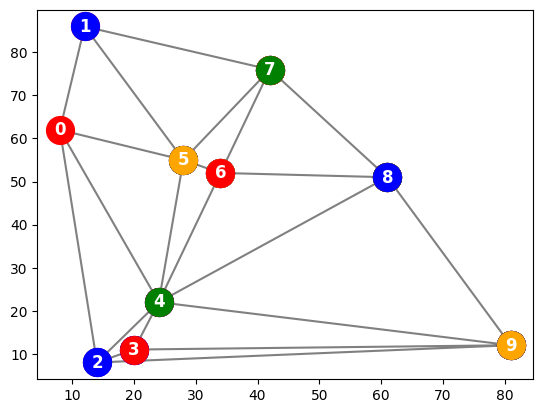

In [9]:
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")

for i in range(len(points)):
        plt.plot(points[i:,0], points[i:,1], 'o', color = list(res.values())[i], markersize = 20)
        plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

## Assignment

Implement the following graph coloring algorithms:

* Add variable and value ordering to the implementation.
* Add forward checking to the implementation.
* Implement hill climbing local search with the min-conflicts heuristic.

Try to color graphs of several sizes with 3 and 4 colors. For each $n$, generate several random instances, and try to make n as large as you can manage. On average, how many constraints (edges) do your map coloring instances have for each $n$? Report the performance of each search algorithm as a function of $n$. For both variants of backtracking search, you can characterize performance in terms of the number of variable assignments attempted. For hill climbing search, report the number of uphill moves and random restarts required in order to reach a solution. Of course, you can also report raw running times as a function of $n$.

# Bài 3 và Bài 4 – Lab 04 (CSP): Backtracking, MRV, LCV, Forward Checking, Min-Conflicts

Quy ước đo lường:
* **COUNT** = số nút backtracking được kiểm tra (số lần gọi `backtrack`). Đây **không** đồng nhất với số bước của Min-Conflicts.
* **Thời gian** đo bằng `time.perf_counter()`, đơn vị giây, lấy trung bình trên các đồ thị.
* **Thành công (%)** = tỷ lệ đồ thị mà thuật toán tìm được một phép gán đầy đủ và hợp lệ (`complete` và `consistent` cùng đúng).
* Đồ thị mẫu: `np.random.seed(1111)`, n = 10 (đã tạo ở các cell trên). Đồ thị ngẫu nhiên cho thí nghiệm: seed = 0, 1, 2, … (xem cell sinh dữ liệu).

# Bài 3. Backtracking Search và thứ tự chọn biến

## 3.1 Chạy `backtrack_search(csp)` trên đồ thị mẫu

Theo dõi `COUNT`, thời gian chạy và kết quả tô màu. Chạy với miền 4 màu và 3 màu trên cùng đồ thị (seed 1111, n = 10). Cờ mặc định đều tắt nên đây chính là phiên bản gốc.

In [10]:
import time, io, contextlib
import pandas as pd

# Cùng một đồ thị mẫu, hai miền màu
csp4 = csp
csp3 = {'variables': variables,
        'domains': {v: ['red', 'blue', 'green'] for v in variables},
        'constraints': csp['constraints']}

# Cấu hình thuật toán: tên -> (USE_MRV, USE_LCV, USE_FC)
CAU_HINH = {
    'Backtracking (gốc)':       (False, False, False),
    'MRV + Backtracking':       (True,  False, False),
    'Backtracking + LCV':       (False, True,  False),
    'MRV + LCV + Backtracking': (True,  True,  False),
}

USE_MRV, USE_LCV, USE_FC = False, False, False
LIMIT = None
res_goc = {}
for ten_csp, csp_i in [('4 màu', csp4), ('3 màu', csp3)]:
    t0 = time.perf_counter()
    res_goc[ten_csp] = backtrack_search(csp_i)
    t = time.perf_counter() - t0
    print(f"[{ten_csp}] COUNT = {COUNT}, thời gian = {t:.6f} s")
    print(f"[{ten_csp}] kết quả:", res_goc[ten_csp])
    if res_goc[ten_csp] is not None:
        print(f"[{ten_csp}] complete = {complete(res_goc[ten_csp], csp_i)}, consistent = {consistent(res_goc[ten_csp], csp_i)}")
    print()

Checked nodes: 11
[4 màu] COUNT = 11, thời gian = 0.000448 s
[4 màu] kết quả: {'0': 'red', '1': 'blue', '2': 'blue', '3': 'red', '4': 'green', '5': 'orange', '6': 'red', '7': 'green', '8': 'blue', '9': 'orange'}
[4 màu] complete = True, consistent = True

Checked nodes: 70
[3 màu] COUNT = 70, thời gian = 0.000592 s
[3 màu] kết quả: None



Trực quan hóa lời giải của phiên bản gốc (4 màu). Lưu ý: khi vẽ phải lấy màu theo tên đỉnh `res[str(i)]` (không lấy theo thứ tự `res.values()`), vì thứ tự chèn vào dict sẽ khác thứ tự đỉnh khi dùng MRV.

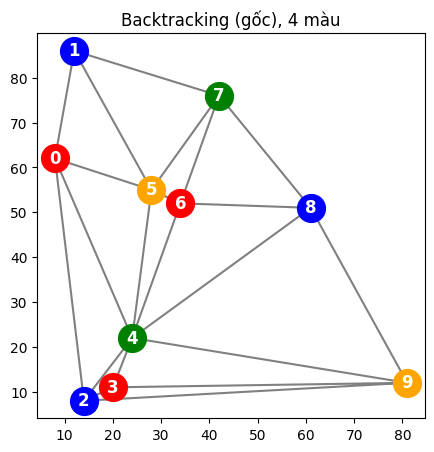

In [11]:
plt.figure(figsize=(5, 5))
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")
for i in range(len(points)):
    plt.plot(points[i,0], points[i,1], 'o', color = res_goc['4 màu'][str(i)], markersize = 20)
    plt.annotate(i, points[i,:], color='white', fontsize="large", weight='heavy',
                 horizontalalignment='center', verticalalignment='center')
plt.title("Backtracking (gốc), 4 màu")
plt.show()

## 3.2 Phân tích `select_unassigned_var()` và cài đặt MRV

**Phiên bản ban đầu** luôn trả về biến chưa gán *đứng đầu danh sách* `csp['variables']` (0, 1, 2, …), bất kể miền của biến đó còn bao nhiêu giá trị hợp lệ. Vì vậy nó có thể chọn một biến còn rất nhiều lựa chọn, trong khi một biến khác đã gần hết màu thì phải chờ, và lỗi chỉ bị phát hiện muộn ở sâu trong cây.

**MRV (Minimum Remaining Values)**: chọn biến chưa gán có **ít giá trị hợp lệ nhất** (giá trị nằm trong miền và không trùng màu với đỉnh kề đã gán). Biến "khó nhất" được xử lý trước nên nhánh sai bị cắt sớm hơn. Khi hòa, giữ biến đứng trước.

Mã MRV nằm trong hàm `select_unassigned_var` ở trên (bật bằng `USE_MRV = True`). Chạy MRV trên cùng đồ thị mẫu:

In [12]:
USE_MRV, USE_LCV, USE_FC = True, False, False
res_mrv = {}
for ten_csp, csp_i in [('4 màu', csp4), ('3 màu', csp3)]:
    t0 = time.perf_counter()
    res_mrv[ten_csp] = backtrack_search(csp_i)
    t = time.perf_counter() - t0
    print(f"[MRV, {ten_csp}] COUNT = {COUNT}, thời gian = {t:.6f} s")
    print(f"[MRV, {ten_csp}] kết quả:", res_mrv[ten_csp])
    if res_mrv[ten_csp] is not None:
        print(f"[MRV, {ten_csp}] complete = {complete(res_mrv[ten_csp], csp_i)}, consistent = {consistent(res_mrv[ten_csp], csp_i)}")
    print()
USE_MRV = False

Checked nodes: 11
[MRV, 4 màu] COUNT = 11, thời gian = 0.001229 s
[MRV, 4 màu] kết quả: {'0': 'red', '1': 'blue', '5': 'green', '4': 'blue', '2': 'green', '3': 'red', '9': 'orange', '6': 'red', '7': 'orange', '8': 'green'}
[MRV, 4 màu] complete = True, consistent = True

Checked nodes: 34
[MRV, 3 màu] COUNT = 34, thời gian = 0.000684 s
[MRV, 3 màu] kết quả: None



## 3.3 Chiến lược thứ tự giá trị: Least Constraining Value (LCV)

LCV thử trước giá trị **loại ít màu nhất** khỏi miền của các láng giềng chưa gán, để giữ nhiều lựa chọn cho các đỉnh còn lại. Mã nằm trong hàm `order_domain` (bật bằng `USE_LCV = True`). Hòa thì giữ thứ tự gốc của miền.

So sánh bốn cấu hình (gốc, MRV, LCV, MRV + LCV) trên **cùng đồ thị mẫu**, với miền 4 màu và 3 màu:

In [13]:
rows_mau = []
res_mau = {}
for ten_csp, csp_i in [('4 màu', csp4), ('3 màu', csp3)]:
    for ten, (USE_MRV, USE_LCV, USE_FC) in CAU_HINH.items():   # gán thẳng vào các cờ toàn cục
        with contextlib.redirect_stdout(io.StringIO()):
            t0 = time.perf_counter()
            r = backtrack_search(csp_i)
            t = time.perf_counter() - t0
        ok = (r is not None) and complete(r, csp_i) and consistent(r, csp_i)
        res_mau[(ten, ten_csp)] = r
        rows_mau.append({'Miền': ten_csp, 'Thuật toán': ten, 'Tìm được nghiệm': ok,
                         'COUNT': COUNT, 'Thời gian (s)': round(t, 6)})
USE_MRV, USE_LCV, USE_FC = False, False, False
print(pd.DataFrame(rows_mau).to_string(index=False))

 Miền               Thuật toán  Tìm được nghiệm  COUNT  Thời gian (s)
4 màu       Backtracking (gốc)             True     11       0.000128
4 màu       MRV + Backtracking             True     11       0.000105
4 màu       Backtracking + LCV             True     11       0.000137
4 màu MRV + LCV + Backtracking             True     11       0.000158
3 màu       Backtracking (gốc)            False     70       0.000535
3 màu       MRV + Backtracking            False     34       0.000313
3 màu       Backtracking + LCV            False     70       0.000891
3 màu MRV + LCV + Backtracking            False     34       0.000581


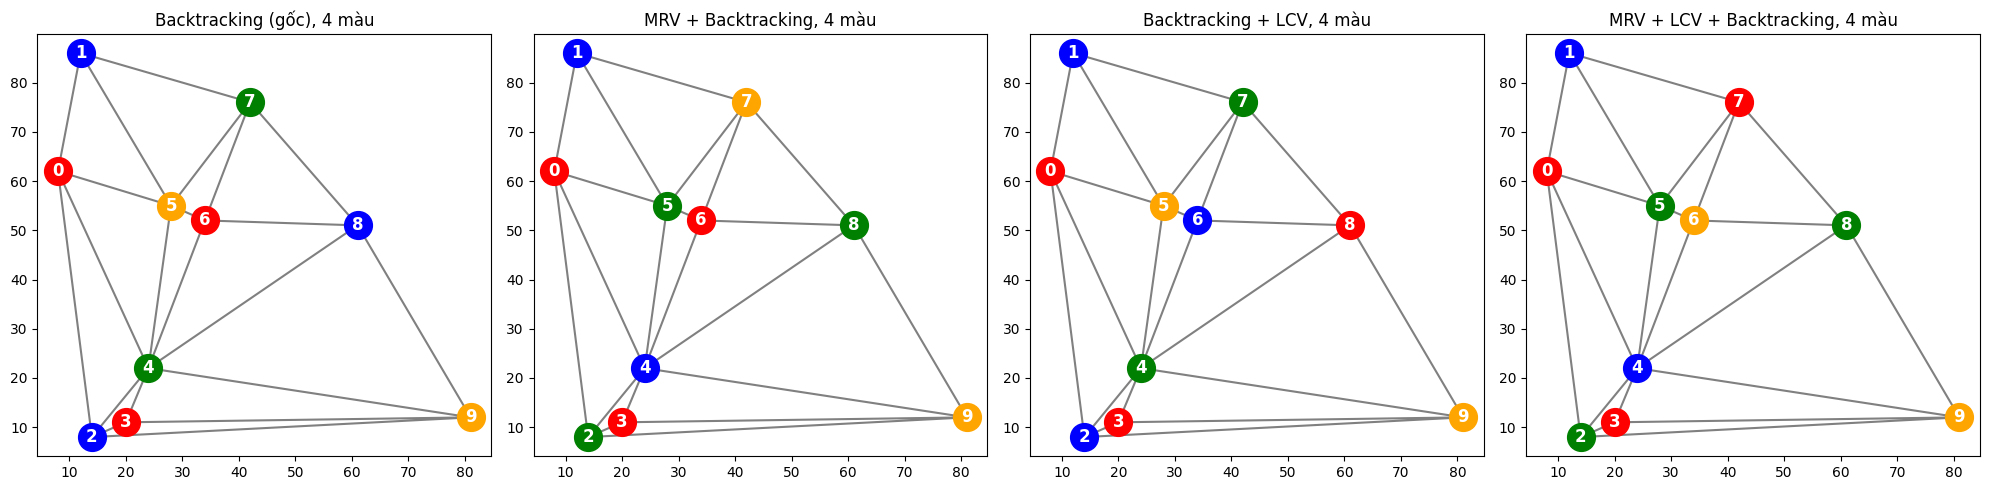

In [14]:
ds = [(ten, res_mau[(ten, '4 màu')]) for ten in CAU_HINH]
fig, axes = plt.subplots(1, len(ds), figsize=(5*len(ds), 5))
for ax, (ten, r) in zip(axes, ds):
    ax.triplot(points[:,0], points[:,1], tri.simplices, color="gray")
    for i in range(len(points)):
        ax.plot(points[i,0], points[i,1], 'o', color=r[str(i)], markersize=20)
        ax.annotate(i, points[i,:], color='white', fontsize="large", weight='heavy',
                    horizontalalignment='center', verticalalignment='center')
    ax.set_title(ten + ", 4 màu")
plt.tight_layout()
plt.show()

## 3.4 Thí nghiệm trên nhiều đồ thị ngẫu nhiên (dùng chung cho Bài 3 và Bài 4)

Một đồ thị duy nhất chưa đủ để kết luận, nên sinh nhiều đồ thị ngẫu nhiên theo đúng cách của notebook gốc (điểm ngẫu nhiên → tam giác hóa Delaunay → ràng buộc cho cạnh i < j). Mỗi đồ thị dùng seed riêng (`np.random.seed(seed)`), nên kết quả lặp lại được. Với mỗi kích thước n tạo `NUM_GRAPHS` đồ thị; cùng một tập đồ thị được dùng cho mọi thuật toán để so sánh công bằng.

In [15]:
NUM_GRAPHS = 100                 # số đồ thị ngẫu nhiên cho mỗi kích thước n (seed = 0 .. 99)
SIZES = [10, 20, 30, 40, 50]     # các kích thước n khảo sát
DOMAIN4 = ['red', 'blue', 'green', 'orange']
DOMAIN3 = ['red', 'blue', 'green']

GRAPHS = {}                      # (n, seed) -> tập ràng buộc
for n_i in SIZES:
    for seed in range(NUM_GRAPHS):
        np.random.seed(seed)
        pts = np.random.randint(100, size=(n_i, 2))
        pts = pts[np.argsort(pts[:,0]), :]
        tr = Delaunay(pts)
        (ip, ind) = tr.vertex_neighbor_vertices
        cons = {}
        for k in range(len(ip)-1):
            for j in np.sort(ind[ip[k]:ip[k+1]]):
                if(k<j): cons[tuple([str(k), str(j)])] = True
        GRAPHS[(n_i, seed)] = list(cons.keys())

def tao_csp(n_i, seed, so_mau):   # dựng csp cùng định dạng với notebook gốc
    vs = [str(v) for v in range(n_i)]
    dom = DOMAIN4 if so_mau == 4 else DOMAIN3
    return {'variables': vs, 'domains': {v: dom for v in vs}, 'constraints': GRAPHS[(n_i, seed)]}

# Số cạnh trung bình theo n (câu hỏi của phần Assignment)
print(pd.DataFrame({'n': SIZES,
                    'Số cạnh trung bình': [np.mean([len(GRAPHS[(n_i, s)]) for s in range(NUM_GRAPHS)]) for n_i in SIZES]}).to_string(index=False))

 n  Số cạnh trung bình
10               20.99
20               49.23
30               78.06
40              107.21
50              136.47


In [16]:
KET_QUA = []   # mỗi dòng: một (thuật toán, n, số màu, seed)

def chay_backtracking(ten, n_i, so_mau):
    global USE_MRV, USE_LCV, USE_FC, LIMIT
    USE_MRV, USE_LCV, USE_FC = CAU_HINH[ten]
    LIMIT = 20000        # tiêu chí dừng: tối đa 20000 nút cho mỗi đồ thị
    for seed in range(NUM_GRAPHS):
        csp_i = tao_csp(n_i, seed, so_mau)
        with contextlib.redirect_stdout(io.StringIO()):
            t0 = time.perf_counter()
            r = backtrack_search(csp_i)
            t = time.perf_counter() - t0
        ok = (r is not None) and complete(r, csp_i) and consistent(r, csp_i)
        trang_thai = 'có nghiệm' if ok else ('hết giới hạn' if LIMIT_HIT else 'vô nghiệm')
        KET_QUA.append({'Thuật toán': ten, 'n': n_i, 'Số màu': so_mau, 'seed': seed, 'Thành công': ok,
                        'Trạng thái': trang_thai, 'COUNT': COUNT, 'Xung đột cuối': 0 if ok else np.nan,
                        'Bước': np.nan, 'Thời gian': t})
    USE_MRV, USE_LCV, USE_FC, LIMIT = False, False, False, None

Chạy 4 cấu hình backtracking của Bài 3 (gốc, MRV, LCV, MRV + LCV) trên 100 đồ thị n = 10, với 4 màu và 3 màu. Dòng nào bị dừng vì chạm giới hạn 20000 nút được ghi là **hết giới hạn** (khác với **vô nghiệm** đã được chứng minh do duyệt hết không gian).

In [17]:
for so_mau in [4, 3]:
    for ten in CAU_HINH:
        chay_backtracking(ten, 10, so_mau)

df = pd.DataFrame(KET_QUA)
bai3 = (df[df['n'] == 10].groupby(['Số màu', 'Thuật toán'], sort=False)
          .agg(**{'Thành công (%)': ('Thành công', lambda s: 100*s.mean()),
                  'COUNT trung bình': ('COUNT', 'mean'),
                  'COUNT lớn nhất': ('COUNT', 'max'),
                  'Thời gian TB (s)': ('Thời gian', 'mean')}).round(6))
print(bai3.to_string())

                                 Thành công (%)  COUNT trung bình  COUNT lớn nhất  Thời gian TB (s)
Số màu Thuật toán                                                                                  
4      Backtracking (gốc)                 100.0             11.99              25          0.000121
       MRV + Backtracking                 100.0             11.25              18          0.000113
       Backtracking + LCV                 100.0             11.66              25          0.000223
       MRV + LCV + Backtracking           100.0             11.23              16          0.000248
3      Backtracking (gốc)                   5.0             48.77             112          0.000354
       MRV + Backtracking                   5.0             33.27              52          0.000315
       Backtracking + LCV                   5.0             48.73             112          0.000703
       MRV + LCV + Backtracking             5.0             33.27              52          0.000493


### Nhận xét Bài 3
**Trên đồ thị mẫu (seed 1111, n = 10):**
* Với 4 màu, cả bốn cấu hình (gốc, MRV, LCV, MRV + LCV) đều có `COUNT = 11`, tức là chỉ gồm 1 nút gốc + 10 lần gán, **không phải quay lui lần nào**. Đồ thị này quá dễ nên heuristic không có gì để cải thiện, và kết quả vẫn hợp lệ (`complete` và `consistent` đều đúng).
* Với 3 màu, đồ thị **vô nghiệm**: phiên bản gốc kiểm tra 70 nút, MRV còn 34 nút, LCV vẫn 70 nút, MRV + LCV là 34 nút. Cả bốn đều trả về `None` sau khi duyệt hết không gian, nên đây là **chứng minh vô nghiệm**, không phải hết giới hạn tính toán.

**Trên 100 đồ thị ngẫu nhiên n = 10:**
* 4 màu: tất cả thành công 100%. COUNT trung bình lần lượt là 11.99 (gốc), 11.25 (MRV), 11.66 (LCV), 11.23 (MRV + LCV); COUNT lớn nhất là 25, 18, 25, 16. MRV giảm cả COUNT trung bình lẫn các trường hợp xấu nhất.
* 3 màu: chỉ 5/100 đồ thị có nghiệm (thành công 5%), 95/100 đồ thị vô nghiệm và đều được chứng minh. COUNT trung bình giảm từ 48.77 (gốc) xuống 33.27 (MRV); LCV gần như không đổi (48.73) vì khi bài toán vô nghiệm thì mọi giá trị đều phải thử hết, thứ tự giá trị không giúp được gì.
* **Kết luận:** MRV là heuristic hiệu quả hơn cả; LCV chỉ có ích khi bài toán có nghiệm và việc chọn sai giá trị gây quay lui, nên ở đây gần như không có tác dụng (thậm chí tốn thêm thời gian mỗi nút để tính điểm LCV: thời gian trung bình của LCV lớn hơn bản gốc dù COUNT gần bằng).
* Hạn chế: n = 10 quá nhỏ nên chênh lệch thời gian chỉ cỡ 10⁻⁴ s; phần Bài 4 bên dưới dùng n lớn hơn để thấy rõ khác biệt.

# Bài 4. Forward Checking và Min-Conflicts

## 4.1 Forward Checking

Sau khi gán màu `c` cho đỉnh `v`, hàm `inference_fails` **loại `c` khỏi miền của các đỉnh kề chưa gán** (`FC_DOMAINS`). Nếu một đỉnh kề bị rỗng miền thì thất bại ngay (không cần đệ quy sâu hơn). Khi quay lui, các giá trị đã loại được **hoàn tác** đúng vị trí cũ trong miền (danh sách `removed`). Bật bằng `USE_FC = True`.

Trước hết kiểm tra FC trên đồ thị mẫu, đồng thời kiểm tra việc hoàn tác miền: sau khi tìm kiếm kết thúc (đặc biệt khi thất bại và phải quay lui hết) các miền phải trở về trạng thái ban đầu.

In [18]:
CAU_HINH['Forward Checking'] = (False, False, True)
CAU_HINH['MRV + Forward Checking'] = (True, False, True)

for ten_csp, csp_i in [('4 màu', csp4), ('3 màu', csp3)]:
    USE_MRV, USE_LCV, USE_FC = CAU_HINH['Forward Checking']
    t0 = time.perf_counter()
    r = backtrack_search(csp_i)
    t = time.perf_counter() - t0
    print(f"[Forward Checking, {ten_csp}] COUNT = {COUNT}, thời gian = {t:.6f} s")
    print(f"[Forward Checking, {ten_csp}] kết quả:", r)
    if r is not None:
        print(f"[Forward Checking, {ten_csp}] complete = {complete(r, csp_i)}, consistent = {consistent(r, csp_i)}")
    if r is None:   # tìm kiếm quay lui hết: miền phải được hoàn tác nguyên vẹn
        print("Miền được hoàn tác đầy đủ sau khi quay lui hết:", all(FC_DOMAINS[v] == csp_i['domains'][v] for v in csp_i['variables']))
    print()
USE_MRV, USE_LCV, USE_FC = False, False, False

Checked nodes: 11
[Forward Checking, 4 màu] COUNT = 11, thời gian = 0.001064 s
[Forward Checking, 4 màu] kết quả: {'0': 'red', '1': 'blue', '2': 'blue', '3': 'red', '4': 'green', '5': 'orange', '6': 'red', '7': 'green', '8': 'blue', '9': 'orange'}
[Forward Checking, 4 màu] complete = True, consistent = True

Checked nodes: 34
[Forward Checking, 3 màu] COUNT = 34, thời gian = 0.000355 s
[Forward Checking, 3 màu] kết quả: None
Miền được hoàn tác đầy đủ sau khi quay lui hết: True



## 4.2 Min-Conflicts (Hill Climbing với heuristic min-conflicts)

Theo yêu cầu của phần *Assignment*:
1. **Khởi tạo một phép gán đầy đủ** ngẫu nhiên (mỗi đỉnh một màu ngẫu nhiên trong miền).
2. Lặp: nếu không còn đỉnh nào vi phạm thì dừng (đã là nghiệm). Ngược lại **chọn ngẫu nhiên một đỉnh đang vi phạm** (có đỉnh kề cùng màu) và **đổi sang màu làm số ràng buộc vi phạm ít nhất** (hòa thì chọn ngẫu nhiên).
3. Tiêu chí dừng: tối đa `max_steps` bước cho mỗi lần khởi tạo; nếu chưa xong thì **khởi động lại ngẫu nhiên** (random restart), tối đa `max_restarts` lần. Hết cả hai giới hạn mà vẫn còn xung đột thì xem là thất bại.

Hàm trả về `(phép gán cuối, tổng số bước, số lần khởi động lại)`. Min-Conflicts là tìm kiếm cục bộ nên **không chứng minh được vô nghiệm**: thất bại chỉ nghĩa là chưa tìm thấy trong giới hạn.

In [19]:
def min_conflicts(csp, max_steps=500, max_restarts=5):
    global NEIGHBORS
    NEIGHBORS = {v: [] for v in csp['variables']}
    for (a, b) in csp['constraints']:
        NEIGHBORS[a].append(b)
        NEIGHBORS[b].append(a)
    
    steps = 0
    for restart in range(max_restarts + 1):
        # phép gán đầy đủ ngẫu nhiên
        assignment = {v: csp['domains'][v][np.random.randint(len(csp['domains'][v]))] for v in csp['variables']}
        for step in range(max_steps + 1):
            conflicted = [v for v in csp['variables'] if any(assignment[u] == assignment[v] for u in NEIGHBORS[v])]
            if len(conflicted) == 0: return(assignment, steps, restart)
            if step == max_steps: break
            var = conflicted[np.random.randint(len(conflicted))]
            counts = [sum(assignment[u] == c for u in NEIGHBORS[var]) for c in csp['domains'][var]]
            best = [c for c, k in zip(csp['domains'][var], counts) if k == min(counts)]
            assignment[var] = best[np.random.randint(len(best))]
            steps += 1
    return(assignment, steps, max_restarts)

# Chạy thử trên đồ thị mẫu (seed 1111)
res_mc = {}
for ten_csp, csp_i in [('4 màu', csp4), ('3 màu', csp3)]:
    np.random.seed(0)
    t0 = time.perf_counter()
    r, steps, restarts = min_conflicts(csp_i)
    t = time.perf_counter() - t0
    ok = complete(r, csp_i) and consistent(r, csp_i)
    n_conf = sum(r[a] == r[b] for (a, b) in csp_i['constraints'])
    res_mc[ten_csp] = r
    print(f"[Min-Conflicts, {ten_csp}] thành công = {ok}, số bước = {steps}, khởi động lại = {restarts}, "
          f"xung đột cuối = {n_conf}, thời gian = {t:.6f} s")

[Min-Conflicts, 4 màu] thành công = True, số bước = 6, khởi động lại = 0, xung đột cuối = 0, thời gian = 0.000135 s
[Min-Conflicts, 3 màu] thành công = False, số bước = 3000, khởi động lại = 5, xung đột cuối = 2, thời gian = 0.028825 s


Checked nodes: 11


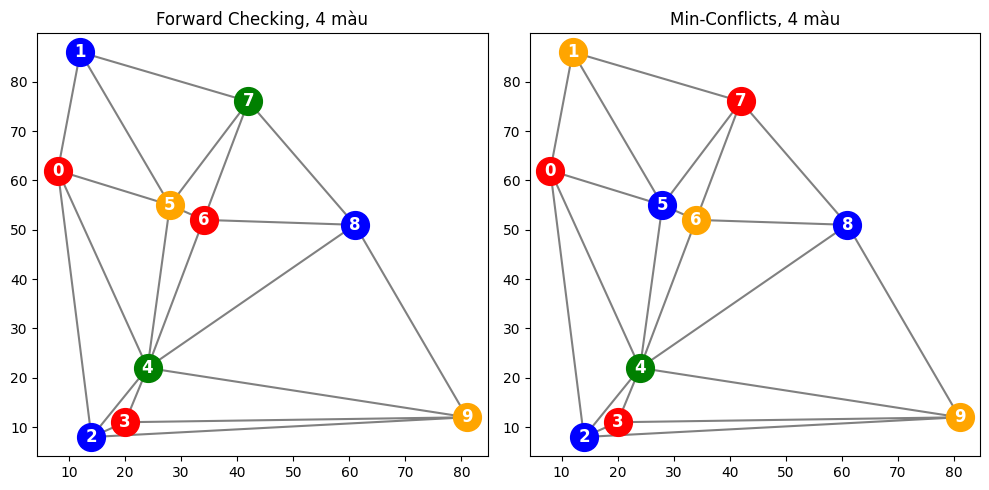

In [20]:
# Hình tô màu của Min-Conflicts và Forward Checking trên đồ thị mẫu (4 màu)
USE_MRV, USE_LCV, USE_FC = CAU_HINH['Forward Checking']
r_fc = backtrack_search(csp4)
USE_MRV, USE_LCV, USE_FC = False, False, False
ds = [('Forward Checking, 4 màu', r_fc), ('Min-Conflicts, 4 màu', res_mc['4 màu'])]
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (ten, r) in zip(axes, ds):
    ax.triplot(points[:,0], points[:,1], tri.simplices, color="gray")
    for i in range(len(points)):
        ax.plot(points[i,0], points[i,1], 'o', color=r[str(i)], markersize=20)
        ax.annotate(i, points[i,:], color='white', fontsize="large", weight='heavy',
                    horizontalalignment='center', verticalalignment='center')
    ax.set_title(ten)
plt.tight_layout()
plt.show()

## 4.3 So sánh trên nhiều n khác nhau, miền 3 và 4 màu

Với mỗi n ∈ {10, 20, 30, 40, 50} và mỗi số màu ∈ {3, 4}, chạy **cùng 100 đồ thị ngẫu nhiên** cho: Backtracking, MRV + Backtracking, Forward Checking, MRV + Forward Checking và Min-Conflicts. Backtracking gốc/MRV đã chạy n = 10 ở Bài 3 nên chỉ chạy bổ sung các n còn lại. Min-Conflicts dùng `np.random.seed(seed)` cho từng đồ thị (cùng seed với đồ thị) để lặp lại được. Tiêu chí dừng: backtracking tối đa 20000 nút; Min-Conflicts tối đa 500 bước × (1 + 5 lần khởi động lại).

In [21]:
# Backtracking gốc và MRV: các n còn lại; FC và MRV + FC: mọi n
for so_mau in [4, 3]:
    for n_i in SIZES:
        for ten in ['Backtracking (gốc)', 'MRV + Backtracking']:
            if n_i != 10: chay_backtracking(ten, n_i, so_mau)
        for ten in ['Forward Checking', 'MRV + Forward Checking']:
            chay_backtracking(ten, n_i, so_mau)

# Min-Conflicts
for so_mau in [4, 3]:
    for n_i in SIZES:
        for seed in range(NUM_GRAPHS):
            csp_i = tao_csp(n_i, seed, so_mau)
            np.random.seed(seed)
            t0 = time.perf_counter()
            r, steps, restarts = min_conflicts(csp_i, max_steps=500, max_restarts=5)
            t = time.perf_counter() - t0
            ok = complete(r, csp_i) and consistent(r, csp_i)
            n_conf = sum(r[a] == r[b] for (a, b) in csp_i['constraints'])
            KET_QUA.append({'Thuật toán': 'Min-Conflicts', 'n': n_i, 'Số màu': so_mau, 'seed': seed, 'Thành công': ok,
                            'Trạng thái': 'có nghiệm' if ok else 'chưa tìm thấy', 'COUNT': np.nan,
                            'Xung đột cuối': n_conf, 'Bước': steps, 'Khởi động lại': restarts, 'Thời gian': t})
df = pd.DataFrame(KET_QUA)
print("Số lượt đã chạy:", len(df))

Số lượt đã chạy: 5400


### Bảng chi tiết (mọi thuật toán, mọi n, 3/4 màu)

`Có nghiệm` / `Vô nghiệm` / `Hết giới hạn` là số đồ thị (trên tổng 100) ứng với từng trạng thái của backtracking. `Vô nghiệm` ở backtracking là **đã chứng minh** (duyệt hết không gian); `Hết giới hạn` là chưa kết luận được. Với Min-Conflicts, đồ thị không tìm thấy nghiệm được tính là `chưa tìm thấy`.

In [22]:
def tong_hop(g):
    return pd.Series({
        'Thành công (%)': 100*g['Thành công'].mean(),
        'COUNT TB': g['COUNT'].mean(),
        'Bước TB': g['Bước'].mean(),
        'Xung đột cuối TB': g['Xung đột cuối'].mean(),
        'Thời gian TB (s)': g['Thời gian'].mean(),
        'Có nghiệm': (g['Trạng thái'] == 'có nghiệm').sum(),
        'Vô nghiệm': (g['Trạng thái'] == 'vô nghiệm').sum(),
        'Hết giới hạn': (g['Trạng thái'] == 'hết giới hạn').sum(),
        'Chưa tìm thấy': (g['Trạng thái'] == 'chưa tìm thấy').sum()})

chi_tiet = df.groupby(['Số màu', 'n', 'Thuật toán'], sort=False).apply(tong_hop, include_groups=False)
chi_tiet = chi_tiet.sort_index(level=[0, 1], ascending=[False, True])
pd.set_option('display.width', 250)
pd.set_option('display.max_rows', 200)
print(chi_tiet.round(6).to_string())

                                    Thành công (%)  COUNT TB  Bước TB  Xung đột cuối TB  Thời gian TB (s)  Có nghiệm  Vô nghiệm  Hết giới hạn  Chưa tìm thấy
Số màu n  Thuật toán                                                                                                                                        
4      10 Backtracking (gốc)                 100.0     11.99      NaN              0.00          0.000121      100.0        0.0           0.0            0.0
          MRV + Backtracking                 100.0     11.25      NaN              0.00          0.000113      100.0        0.0           0.0            0.0
          Backtracking + LCV                 100.0     11.66      NaN              0.00          0.000223      100.0        0.0           0.0            0.0
          MRV + LCV + Backtracking           100.0     11.23      NaN              0.00          0.000248      100.0        0.0           0.0            0.0
          Forward Checking                   100.0     11.

### Biểu đồ so sánh theo n (4 màu và 3 màu)

Hai biểu đồ phân tích: (1) số nút COUNT / số bước theo n (trục log), (2) thời gian chạy trung bình theo n (trục log).

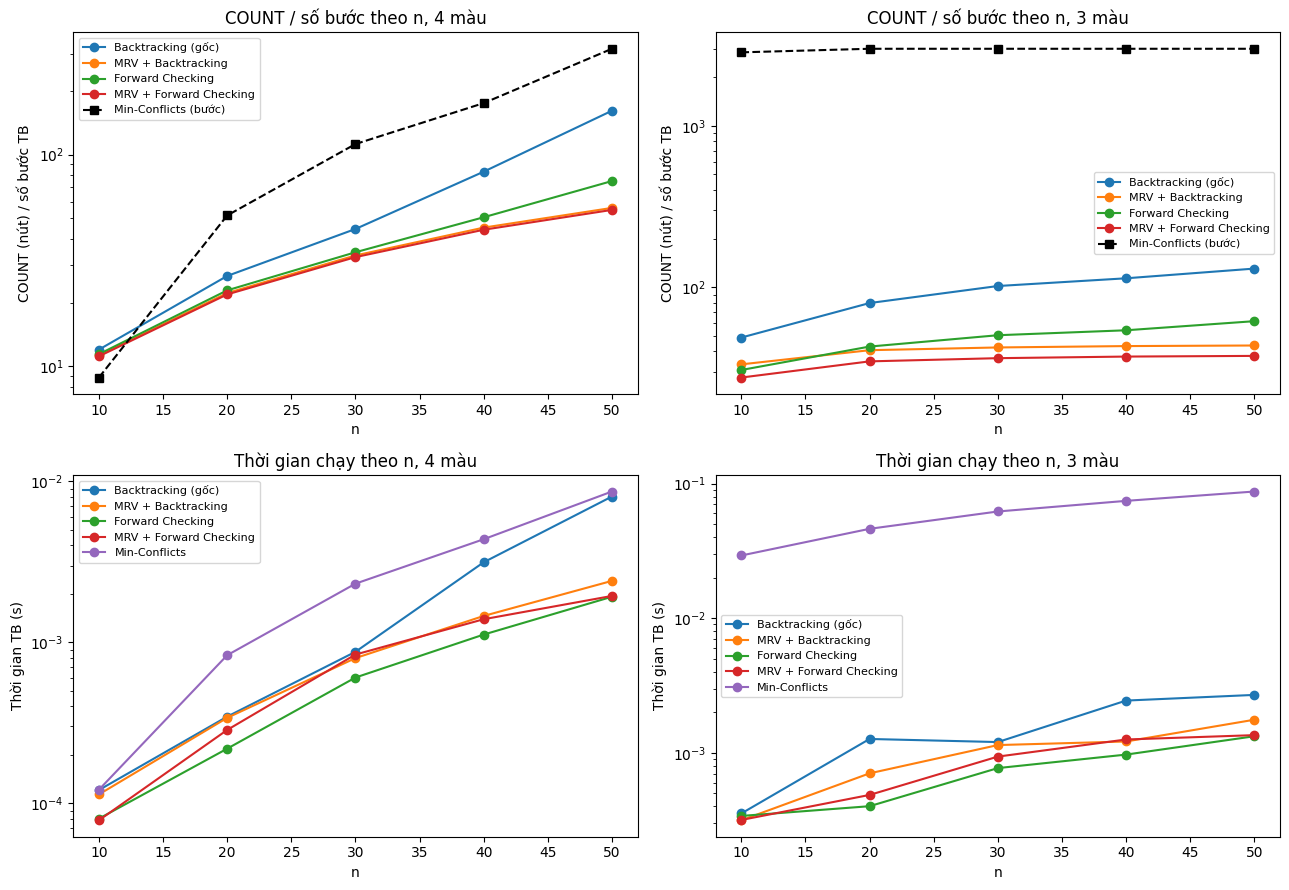

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for col, so_mau in enumerate([4, 3]):
    d = df[df['Số màu'] == so_mau]
    for ten in ['Backtracking (gốc)', 'MRV + Backtracking', 'Forward Checking', 'MRV + Forward Checking']:
        g = d[d['Thuật toán'] == ten].groupby('n')['COUNT'].mean()
        axes[0, col].plot(g.index, g.values, 'o-', label=ten)
    g = d[d['Thuật toán'] == 'Min-Conflicts'].groupby('n')['Bước'].mean()
    axes[0, col].plot(g.index, g.values, 's--', color='black', label='Min-Conflicts (bước)')
    axes[0, col].set_yscale('log'); axes[0, col].set_xlabel('n'); axes[0, col].set_ylabel('COUNT (nút) / số bước TB')
    axes[0, col].set_title(f'COUNT / số bước theo n, {so_mau} màu'); axes[0, col].legend(fontsize=8)
    for ten in ['Backtracking (gốc)', 'MRV + Backtracking', 'Forward Checking', 'MRV + Forward Checking', 'Min-Conflicts']:
        g = d[d['Thuật toán'] == ten].groupby('n')['Thời gian'].mean()
        axes[1, col].plot(g.index, g.values, 'o-', label=ten)
    axes[1, col].set_yscale('log'); axes[1, col].set_xlabel('n'); axes[1, col].set_ylabel('Thời gian TB (s)')
    axes[1, col].set_title(f'Thời gian chạy theo n, {so_mau} màu'); axes[1, col].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Bảng 4.2 – Bảng ghi kết quả thí nghiệm

* Mỗi dòng là trung bình trên **100 đồ thị ngẫu nhiên** (seed 0 … 99), cùng một tập đồ thị cho mọi thuật toán.
* **Thành công (%)**: % đồ thị tìm được phép gán đầy đủ, hợp lệ. Với 3 màu, nhiều đồ thị **vô nghiệm** nên không thể đạt 100% dù thuật toán đúng.
* **Xung đột / COUNT**: backtracking ghi COUNT trung bình (số nút kiểm tra); Min-Conflicts ghi số bước trung bình và số ràng buộc vi phạm còn lại trung bình ở cuối (0 nếu thành công). COUNT và số bước **không** cùng đơn vị.
* **Thời gian (s)**: trung bình mỗi đồ thị, đo bằng `time.perf_counter()`.
* Tiêu chí dừng: backtracking tối đa 20000 nút; Min-Conflicts tối đa 500 bước × (1 + 5 lần khởi động lại).

In [24]:
BANG_4_2_COT = ['Bài toán', 'Kích thước', 'Thuật toán', 'Số màu / lượt', 'Thành công (%)', 'Xung đột / COUNT', 'Thời gian (s)']
dong = []

def them_dong(ten, n_i, so_mau):
    g = df[(df['Thuật toán'] == ten) & (df['n'] == n_i) & (df['Số màu'] == so_mau)]
    if ten == 'Min-Conflicts':
        xd = f"{g['Bước'].mean():.1f} bước; xung đột cuối = {g['Xung đột cuối'].mean():.2f}"
    else:
        xd = f"COUNT = {g['COUNT'].mean():.1f}"
    dong.append(['Tô màu', f'n = {n_i}', ten.replace(' (gốc)', ''), f'{so_mau} màu / {len(g)} lượt',
                 round(100*g['Thành công'].mean(), 1), xd, f"{g['Thời gian'].mean():.6f}"])

them_dong('Backtracking (gốc)', 10, 4)
them_dong('MRV + Backtracking', 10, 4)
them_dong('Forward Checking', 10, 3)
them_dong('Forward Checking', 10, 4)
for so_mau in [3, 4]:
    for n_i in SIZES:
        them_dong('Min-Conflicts', n_i, so_mau)

bang_4_2 = pd.DataFrame(dong, columns=BANG_4_2_COT)
bang_4_2.to_csv('bang_4_2_ket_qua.csv', index=False, encoding='utf-8-sig')   # mở được bằng Excel/Word
print(bang_4_2.to_string(index=False))

Bài toán Kích thước         Thuật toán    Số màu / lượt  Thành công (%)                   Xung đột / COUNT Thời gian (s)
  Tô màu     n = 10       Backtracking 4 màu / 100 lượt           100.0                       COUNT = 12.0      0.000121
  Tô màu     n = 10 MRV + Backtracking 4 màu / 100 lượt           100.0                       COUNT = 11.2      0.000113
  Tô màu     n = 10   Forward Checking 3 màu / 100 lượt             5.0                       COUNT = 30.7      0.000340
  Tô màu     n = 10   Forward Checking 4 màu / 100 lượt           100.0                       COUNT = 11.4      0.000080
  Tô màu     n = 10      Min-Conflicts 3 màu / 100 lượt             5.0  2851.2 bước; xung đột cuối = 1.21      0.029227
  Tô màu     n = 20      Min-Conflicts 3 màu / 100 lượt             0.0  3000.0 bước; xung đột cuối = 3.28      0.046135
  Tô màu     n = 30      Min-Conflicts 3 màu / 100 lượt             0.0  3000.0 bước; xung đột cuối = 6.04      0.062049
  Tô màu     n = 40      Min-Con

### Bảng bổ sung: so sánh các chiến lược của Bài 3

Gồm Backtracking, MRV, LCV, MRV + LCV ở n = 10, cả 4 màu và 3 màu, dùng để so sánh trực tiếp với phiên bản gốc, và Forward Checking có/không có MRV.

In [25]:
dong = []
for so_mau in [4, 3]:
    for ten in ['Backtracking (gốc)', 'MRV + Backtracking', 'Backtracking + LCV', 'MRV + LCV + Backtracking',
                'Forward Checking', 'MRV + Forward Checking']:
        them_dong(ten, 10, so_mau)
bang_bo_sung = pd.DataFrame(dong, columns=BANG_4_2_COT)
bang_bo_sung.to_csv('bang_4_2_bo_sung_so_sanh.csv', index=False, encoding='utf-8-sig')
print(bang_bo_sung.to_string(index=False))

Bài toán Kích thước               Thuật toán    Số màu / lượt  Thành công (%) Xung đột / COUNT Thời gian (s)
  Tô màu     n = 10             Backtracking 4 màu / 100 lượt           100.0     COUNT = 12.0      0.000121
  Tô màu     n = 10       MRV + Backtracking 4 màu / 100 lượt           100.0     COUNT = 11.2      0.000113
  Tô màu     n = 10       Backtracking + LCV 4 màu / 100 lượt           100.0     COUNT = 11.7      0.000223
  Tô màu     n = 10 MRV + LCV + Backtracking 4 màu / 100 lượt           100.0     COUNT = 11.2      0.000248
  Tô màu     n = 10         Forward Checking 4 màu / 100 lượt           100.0     COUNT = 11.4      0.000080
  Tô màu     n = 10   MRV + Forward Checking 4 màu / 100 lượt           100.0     COUNT = 11.2      0.000078
  Tô màu     n = 10             Backtracking 3 màu / 100 lượt             5.0     COUNT = 48.8      0.000354
  Tô màu     n = 10       MRV + Backtracking 3 màu / 100 lượt             5.0     COUNT = 33.3      0.000315
  Tô màu     n = 10

### Nhận xét Bài 4
**Forward Checking (FC):**
* Trên đồ thị mẫu: 4 màu `COUNT = 11` (như bản gốc); 3 màu `COUNT = 34` và trả về `None`, thấp hơn bản gốc (70), bằng MRV nhưng chỉ nhờ lọc miền. Kiểm tra hoàn tác cho kết quả `True`: sau khi quay lui hết, miền của mọi đỉnh trở về đúng như ban đầu.
* Trên 100 đồ thị, n = 50, 4 màu: COUNT trung bình của Backtracking gốc là 161.06, MRV 55.98, Forward Checking 74.97, MRV + Forward Checking 54.78. Với 3 màu (cả 100 đồ thị đều vô nghiệm và đều được chứng minh, không có trường hợp hết giới hạn): 130.42, 43.54, 61.60 và 37.54. Như vậy FC và MRV đều giảm mạnh số nút so với bản gốc, và kết hợp hai chiến lược cho COUNT thấp nhất.
* Chi phí: FC phải cập nhật và hoàn tác miền ở mỗi nút nên mỗi nút tốn nhiều thời gian hơn. Vì vậy ở n nhỏ, thời gian của FC hay MRV + FC chỉ ngang MRV đơn thuần (chi phí quản lý miền bù lại phần nút tiết kiệm được, xem cột thời gian ở bảng chi tiết); lợi ích về COUNT lớn dần khi n tăng hoặc khi bài toán khó (3 màu, chứng minh vô nghiệm).

**Min-Conflicts (khởi tạo đầy đủ, đổi màu đỉnh vi phạm sang màu ít xung đột nhất, tối đa 500 bước × 6 lần khởi tạo):**
* 4 màu: thành công 100% ở mọi n. Số bước trung bình tăng theo n: 8.85 (n = 10), 51.57 (n = 20), 112.09 (n = 30), 174.98 (n = 40), 315.94 (n = 50). Thời gian trung bình vẫn rất nhỏ (dưới 0.01 s).
* 3 màu: thành công 5% ở n = 10 (đúng 5 đồ thị có nghiệm) và **0% ở n ≥ 20**. Chạy hết 3000 bước, số xung đột còn lại trung bình tăng theo n (1.21; 3.28; 6.04; 8.56; 11.97). Min-Conflicts **không thể phân biệt** "bài toán vô nghiệm" với "chưa tìm thấy": nó chỉ báo thất bại sau khi hết giới hạn.
* So sánh: ở 3 màu, backtracking (có hoặc không có FC/MRV) **chứng minh vô nghiệm** chỉ với khoảng 34 đến 130 nút (thời gian cỡ 10⁻³ s), nhanh hơn nhiều so với Min-Conflicts phải tiêu hết 3000 bước (cỡ 10⁻² s) mà vẫn không kết luận được. Ngược lại ở 4 màu, cả hai đều thành công 100%.